# Weather report 2025

Daily measurements from one station: temperature, rain, wind and sunshine.

## Load the data

In [1]:
import pandas as pd

df = pd.read_csv("data/weather.csv", parse_dates=["date"])
df.head()

,date,temp_min,temp_max,rain_mm,wind_kmh,sun_hours
0,2025-01-01,-4.9,4.3,0.9,24.6,0.0
1,2025-01-02,-4.7,5.0,0.0,20.4,6.9
2,2025-01-03,-3.8,3.5,12.6,12.3,0.0
3,2025-01-04,-6.1,1.9,24.7,17.3,0.0
4,2025-01-05,-10.6,3.0,6.3,17.6,1.9


## Temperature

Monthly means of the daily minimum and maximum.

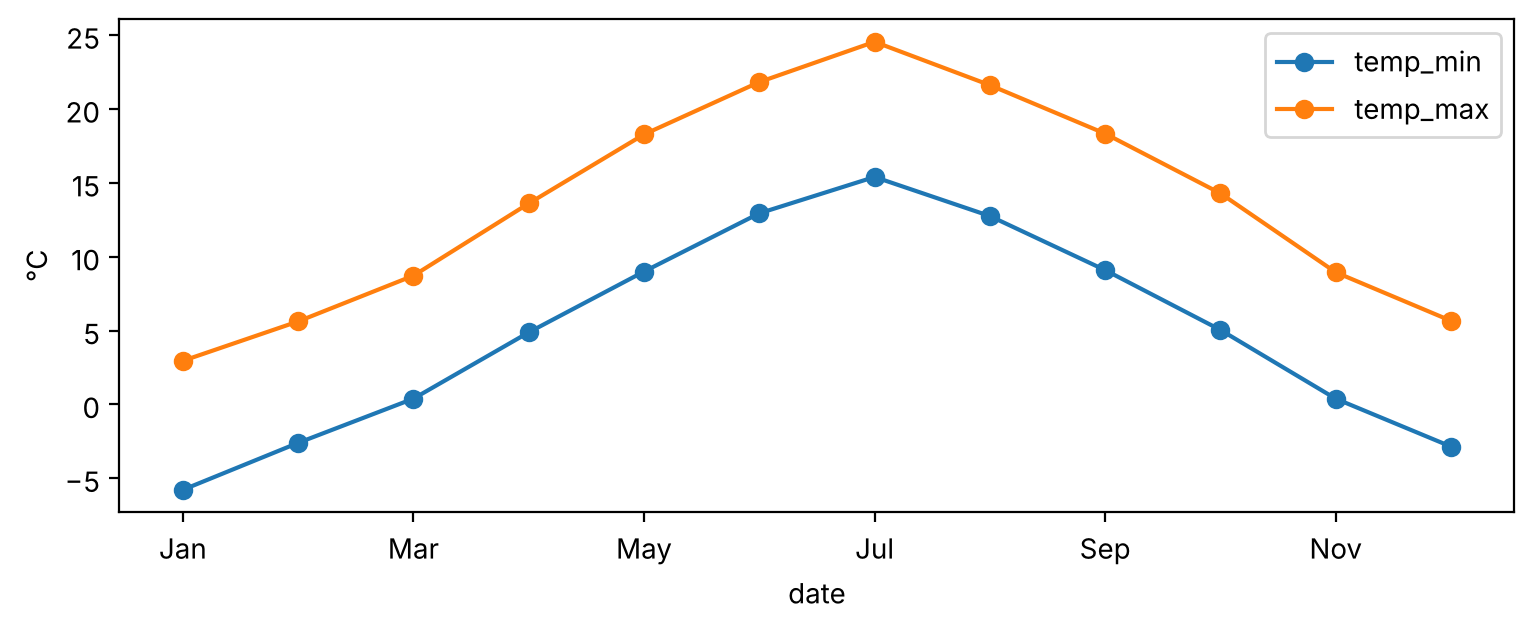

In [2]:
monthly = df.resample("ME", on="date").agg(
    {"temp_min": "mean", "temp_max": "mean", "rain_mm": "sum", "sun_hours": "sum"}
)
monthly.index = monthly.index.strftime("%b")
ax = monthly[["temp_min", "temp_max"]].plot(figsize=(9, 3.2), marker="o")
ax.set_ylabel("°C");

## Rain and sunshine

Total rain and hours of sunshine per month.

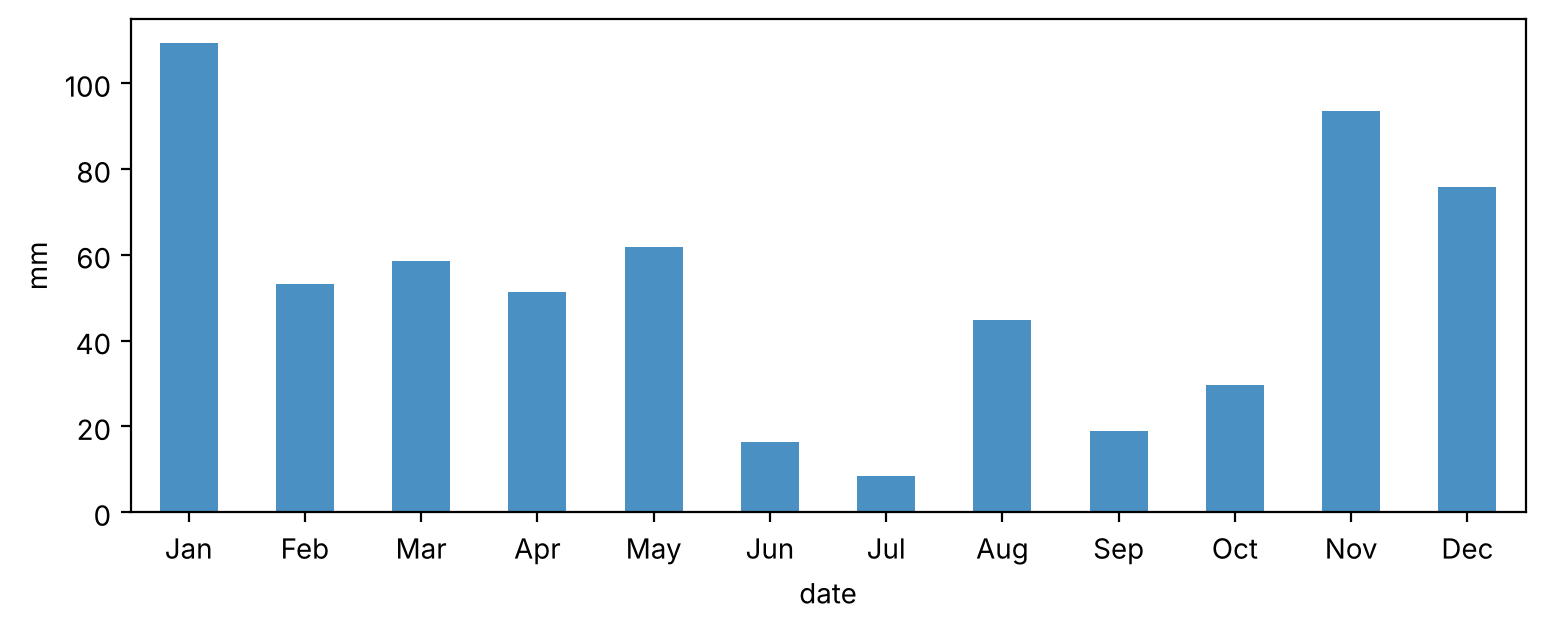

In [3]:
ax = monthly["rain_mm"].plot.bar(figsize=(9, 3.2), color="#4a90c2", rot=0)
ax.set_ylabel("mm");

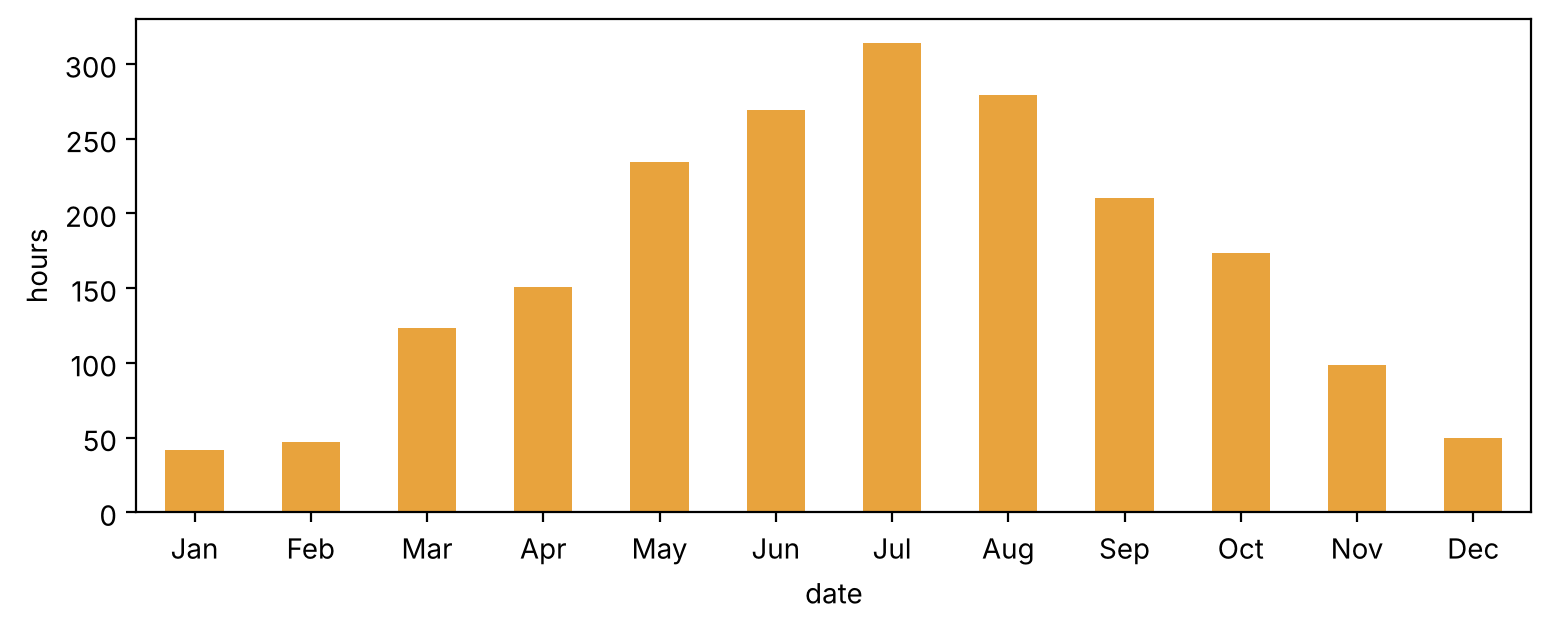

In [4]:
ax = monthly["sun_hours"].plot.bar(figsize=(9, 3.2), color="#e8a33d", rot=0)
ax.set_ylabel("hours");

## Wind

In [5]:
df["wind_kmh"].describe().round(1)

count    365.0
mean      16.1
std        6.2
min        1.0
25%       12.1
50%       15.6
75%       20.0
max       32.7
Name: wind_kmh, dtype: float64

## Summary

- July is the warmest and sunniest month.
- January is the wettest month, with 109 mm of rain.
- The summer is dry: July has less than 10 mm of rain.